# Classificação de ocorrências em São Paulo: roubo × furto com MLP

**Global Solution – Aprendizado Profundo com Redes Neurais Convolucionais**

Integrantes: Enzo Hitoshi Oda (RM567313), Ana Carolina Pereira Lopez (RM568401) e Henrique Fessel Trench (RM567513)

**O que o modelo faz.** Dada uma ocorrência *já registrada* (ou hipotética) de subtração de celular na capital paulista, a MLP estima se ela é mais compatível com **roubo** (art. 157) ou **furto** (art. 155).

## 1. Fonte dos dados

- **SSP-SP – Portal de Estatísticas → Consultas → Bases de Dados → _Celulares Subtraídos_** (arquivo `CelularesSubtraidos_2026.xlsx`, aba `CELULAR_2026`). Endereço: <https://www.ssp.sp.gov.br/estatistica/consultas>
- **Período:** boletins de 2026 com fatos ocorridos entre 01/01/2026 e 30/09/2026 (o último mês disponível na base que baixamos)
- **Por que essa base?** Ela traz a natureza jurídica (`RUBRICA`), que é justamente o que distingue roubo de furto, o município dos fatos (`CIDADE`) e alguns atributos de contexto (bairro, hora, tipo de local, marca do aparelho), sem nenhum dado pessoal


In [1]:
import json, random, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay, classification_report
warnings.filterwarnings("ignore")
SEED = 42
tf.keras.utils.set_random_seed(SEED); tf.config.experimental.enable_op_determinism()
sns.set_theme(style="whitegrid")
print("TensorFlow", tf.__version__)

TensorFlow 2.22.0-rc0


## 3. Exploração dos dados

A amostra foi gerada pelo `src/data_prep.py` (a partir do `.xlsx` da SSP) e salva em `data/amostra_20k.csv`

In [2]:
df = pd.read_csv("data/amostra_20k.csv")
print(df.shape); display(df.head())
print("\nValores ausentes:\n", df.isna().sum().to_string())
print("\nDistribuição das classes:"); print(df.alvo.map({0:"furto", 1:"roubo"}).value_counts(normalize=True).round(3).to_string())
print("\nCardinalidades:\n", df.nunique().to_string())

(20000, 7)


,bairro,periodo,dia_semana,tipo_local,subtipo_local,marca,alvo
0,IPIRANGA,tarde,terça,Via Pública,Via Pública,Apple,0
1,OUTROS,não informado,terça,Via Pública,Via Pública,Outros,0
2,JARDIM PAULISTANO,noite,quinta,Via Pública,Via Pública,Apple,0
3,OUTROS,tarde,sexta,Via Pública,Via Pública,Samsung,0
4,JABAQUARA,noite,segunda,Via Pública,Transeunte,Samsung,0



Valores ausentes:
 bairro           0
periodo          0
dia_semana       0
tipo_local       0
subtipo_local    0
marca            0
alvo             0

Distribuição das classes:
alvo
furto    0.649
roubo    0.351

Cardinalidades:
 bairro           101
periodo            5
dia_semana         7
tipo_local        27
subtipo_local     15
marca              6
alvo               2


Não tem valor ausente nenhum porque os nulos foram tratados lá na preparação: bairro virou `NAO INFORMADO`, período e local viraram `não informado`. A classe roubo é uns 35% da base e furto 65% (desbalanceamento moderado). Por isso, além da acurácia, a gente olha precision/recall/F1 da classe roubo, lembrando que o baseline "sempre furto" já acerta ~65%

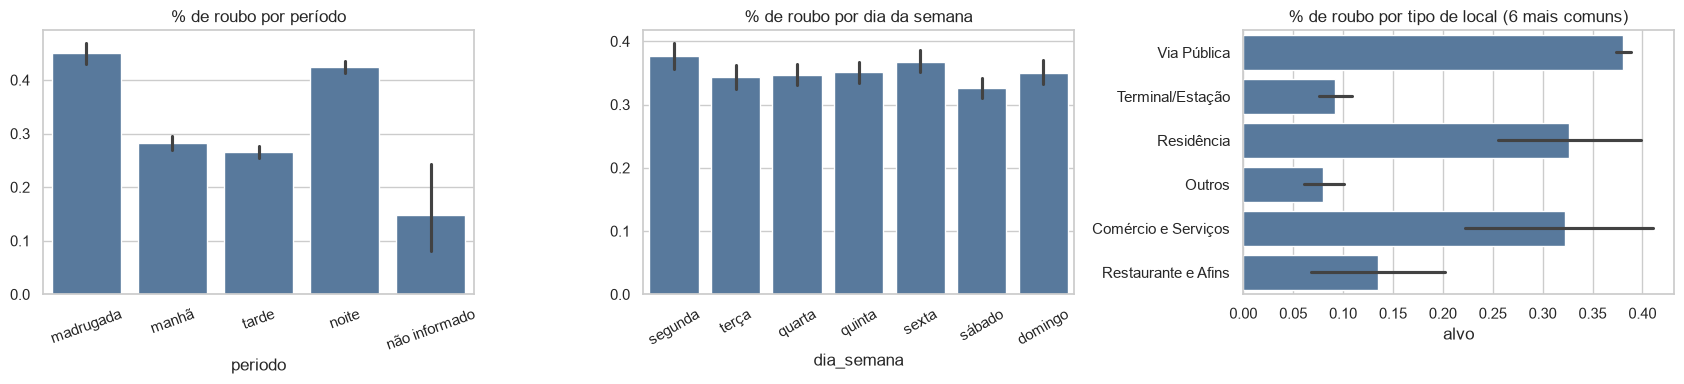

           mean  size
marca                
Apple     0.351  9515
Samsung   0.318  5430
Motorola  0.402  2661
Xiaomi    0.343  1478
Outros    0.403   858
LG        0.362    58


In [3]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
ordem_p = ["madrugada","manhã","tarde","noite","não informado"]
sns.barplot(data=df, x="periodo", y="alvo", order=ordem_p, ax=ax[0], color="#4C78A8"); ax[0].set_title("% de roubo por período"); ax[0].tick_params(axis="x", rotation=20)
ordem_d = ["segunda","terça","quarta","quinta","sexta","sábado","domingo"]
sns.barplot(data=df, x="dia_semana", y="alvo", order=ordem_d, ax=ax[1], color="#4C78A8"); ax[1].set_title("% de roubo por dia da semana"); ax[1].tick_params(axis="x", rotation=30)
top = df.tipo_local.value_counts().index[:6]
sns.barplot(data=df[df.tipo_local.isin(top)], x="alvo", y="tipo_local", ax=ax[2], color="#4C78A8"); ax[2].set_title("% de roubo por tipo de local (6 mais comuns)")
for a in ax: a.set_ylabel("")
plt.tight_layout(); plt.show()
print(df.groupby("marca").alvo.agg(["mean","size"]).round(3).sort_values("size", ascending=False).to_string())

## 4. Preparação: codificação e divisão

A divisão foi estratificada 70/15/15 (treino/validação/teste). A validação serve pra escolher a arquitetura e pro early stopping, e o teste só é usado uma vez, no final

Sobre a codificação: todos os atributos são categóricos, então a gente usou one-hot (`OneHotEncoder`), ajustado só no treino (`handle_unknown="ignore"`), justamente pra nada do teste influenciar o treinamento

Escalonamento não foi necessário. Depois do one-hot todas as entradas já estão em {0, 1}, na mesma escala, e não tem nenhuma variável numérica contínua

In [4]:
FEATURES = ["bairro","periodo","dia_semana","tipo_local","subtipo_local","marca"]
X, y = df[FEATURES], df["alvo"].values
X_tr, X_tmp, y_tr, y_tmp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=SEED)
X_va, X_te, y_va, y_te = train_test_split(X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=SEED)
enc = OneHotEncoder(handle_unknown="ignore", sparse_output=False).fit(X_tr)
Xtr, Xva, Xte = [enc.transform(a).astype("float32") for a in (X_tr, X_va, X_te)]
print("treino", Xtr.shape, "| validação", Xva.shape, "| teste", Xte.shape)
print("% roubo  treino/val/teste:", y_tr.mean().round(3), y_va.mean().round(3), y_te.mean().round(3))
print("Entradas da rede (colunas após one-hot):", Xtr.shape[1])

treino (14000, 160) | validação (3000, 160) | teste (3000, 160)
% roubo  treino/val/teste: 0.351 0.351 0.351
Entradas da rede (colunas após one-hot): 160


## 5. Implementação da MLP e configuração do treinamento

A estrutura geral é `Entrada (n colunas one-hot) → [Dense + ativação (+ Dropout)] × k → Dense(1, sigmoid)`

| Componente | Escolha | Por quê |
|---|---|---|
| Saída | 1 neurônio **sigmoid** | classificação binária, a saída é P(roubo) |
| Perda | **binary cross-entropy** | é a perda natural pra probabilidade Bernoulli e penaliza previsão confiante errada |
| Otimizador | **Adam** | adapta a taxa por parâmetro e converge bem sem precisar de muito ajuste |
| Batch | 128 | equilíbrio razoável entre ruído e velocidade pras 14 mil amostras |
| Épocas | até 100 com **EarlyStopping** (paciência 8, `restore_best_weights`) na `val_loss` | evita overfitting sem ter que fixar um número de épocas |
| Ativação oculta | ReLU (e tanh numa variante) | ReLU evita o gradiente sumir; tanh entrou como comparação |
| Limiar de decisão | 0,5 | padrão, e as classes estão só moderadamente desbalanceadas |

In [5]:
def build_mlp(n_in, hidden, act="relu", dropout=0.0, l2=0.0, lr=1e-3):
    reg = tf.keras.regularizers.l2(l2) if l2 else None
    layers = [tf.keras.Input(shape=(n_in,))]
    for h in hidden:
        layers.append(tf.keras.layers.Dense(h, activation=act, kernel_regularizer=reg))
        if dropout: layers.append(tf.keras.layers.Dropout(dropout))
    layers.append(tf.keras.layers.Dense(1, activation="sigmoid"))
    m = tf.keras.Sequential(layers)
    m.compile(optimizer=tf.keras.optimizers.Adam(lr), loss="binary_crossentropy", metrics=["accuracy"])
    return m

def metricas(y_true, p, thr=0.5):
    yh = (p >= thr).astype(int)
    return dict(acc=accuracy_score(y_true, yh), precision=precision_score(y_true, yh, zero_division=0),
                recall=recall_score(y_true, yh), f1=f1_score(y_true, yh))

build_mlp(Xtr.shape[1], [64, 32]).summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │        10,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,417 (48.50 KB)

 Trainable params: 12,417 (48.50 KB)

 Non-trainable params: 0 (0.00 B)

## 6. Experimentos com arquiteturas

Foram quatro configurações, mudando **uma coisa por vez** em relação à anterior:

| Modelo | Camadas ocultas | O que mudou e por quê |
|---|---|---|
| **A – pequena** | 16 | referência simples, capacidade baixa (risco de *underfitting*) |
| **B – média** | 64 → 32 | mais camadas e neurônios, pra tentar captar interações tipo bairro × período |
| **C – profunda + Dropout** | 128 → 64 → 32, Dropout 0,3 | ainda mais capacidade, com dropout pra segurar o overfitting |
| **D – tanh + L2** | 64 → 32, tanh, L2 = 1e-4, lr = 5e-4 | trocou a ativação, entrou regularização de pesos e uma taxa de aprendizado menor |

In [6]:
CONFIGS = {
    "A – 16":                 dict(hidden=[16]),
    "B – 64-32":              dict(hidden=[64, 32]),
    "C – 128-64-32 + dropout": dict(hidden=[128, 64, 32], dropout=0.3),
    "D – 64-32 tanh + L2":    dict(hidden=[64, 32], act="tanh", l2=1e-4, lr=5e-4),
}
resultados, historicos, modelos = {}, {}, {}
for nome, cfg in CONFIGS.items():
    tf.keras.utils.set_random_seed(SEED)
    m = build_mlp(Xtr.shape[1], **cfg)
    es = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True)
    h = m.fit(Xtr, y_tr, validation_data=(Xva, y_va), epochs=100, batch_size=128, callbacks=[es], verbose=0)
    pva = m.predict(Xva, verbose=0).ravel(); ptr = m.predict(Xtr, verbose=0).ravel()
    best = int(np.argmin(h.history["val_loss"]))
    resultados[nome] = {**{f"val_{k}": v for k, v in metricas(y_va, pva).items()},
                        "train_acc": metricas(y_tr, ptr)["acc"], "val_loss": min(h.history["val_loss"]),
                        "epocas": len(h.history["loss"]), "melhor_epoca": best + 1, "parametros": m.count_params()}
    historicos[nome], modelos[nome] = h.history, m
    print(f"{nome:26s} épocas={len(h.history['loss']):3d} (melhor={best+1:3d})  val_acc={resultados[nome]['val_acc']:.4f}  val_f1={resultados[nome]['val_f1']:.4f}")

A – 16                     épocas= 28 (melhor= 20)  val_acc=0.6973  val_f1=0.5022
B – 64-32                  épocas= 13 (melhor=  5)  val_acc=0.7000  val_f1=0.4989
C – 128-64-32 + dropout    épocas= 13 (melhor=  5)  val_acc=0.6957  val_f1=0.5003
D – 64-32 tanh + L2        épocas= 58 (melhor= 50)  val_acc=0.6980  val_f1=0.5087


### 6.1 Comparação na validação (com baseline)

O baseline "sempre furto" e uma regressão logística (sem camada oculta nenhuma) servem pra mostrar quanto a MLP realmente agrega

In [7]:
base_pred = np.zeros_like(y_va)
lr_ = LogisticRegression(max_iter=1000).fit(Xtr, y_tr); p_lr = lr_.predict_proba(Xva)[:, 1]
tab = pd.DataFrame(resultados).T
tab = tab[["parametros","melhor_epoca","train_acc","val_acc","val_precision","val_recall","val_f1","val_loss"]]
extra = pd.DataFrame({"Baseline – sempre furto": dict(val_acc=accuracy_score(y_va, base_pred), val_precision=0.0, val_recall=0.0, val_f1=0.0),
                      "Regressão logística":     {f"val_{k}": v for k, v in metricas(y_va, p_lr).items()}}).T
display(pd.concat([tab, extra]).round(4))
melhor = max(resultados, key=lambda k: resultados[k]["val_f1"])
print("\nArquitetura escolhida (maior F1 de roubo na validação):", melhor)

,parametros,melhor_epoca,train_acc,val_acc,val_precision,val_recall,val_f1,val_loss
A – 16,2593.0,20.0,0.7214,0.6973,0.5933,0.4354,0.5022,0.5706
B – 64-32,12417.0,5.0,0.7196,0.7000,0.6022,0.4259,0.4989,0.5713
C – 128-64-32 + dropout,30977.0,5.0,0.7204,0.6957,0.5897,0.4344,0.5003,0.5724
D – 64-32 tanh + L2,12417.0,50.0,0.7197,0.6980,0.5922,0.4458,0.5087,0.5800
Baseline – sempre furto,NaN,NaN,NaN,0.6493,0.0000,0.0000,0.0000,NaN
Regressão logística,NaN,NaN,NaN,0.6987,0.5995,0.4240,0.4967,NaN



Arquitetura escolhida (maior F1 de roubo na validação): D – 64-32 tanh + L2


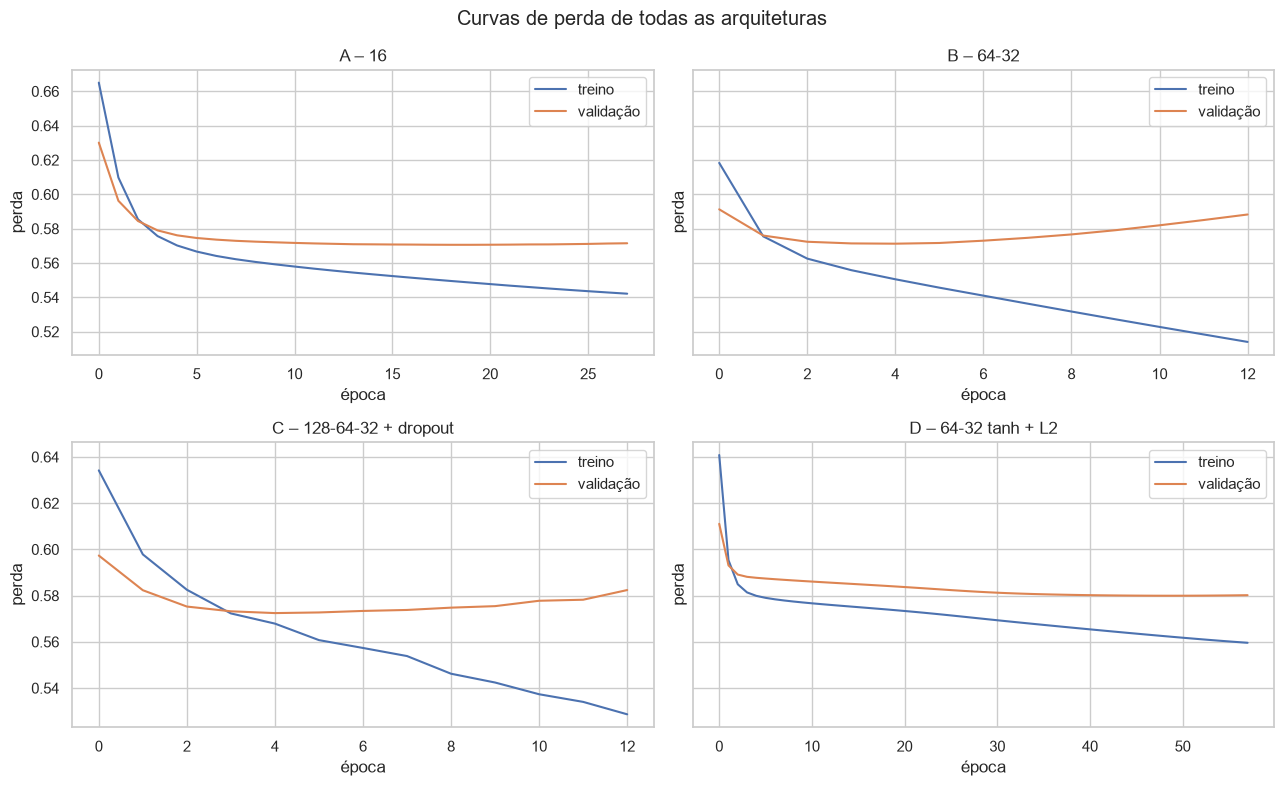

In [8]:
fig, ax = plt.subplots(2, 2, figsize=(13, 8), sharey="row")
for a, (nome, h) in zip(ax.ravel(), historicos.items()):
    a.plot(h["loss"], label="treino"); a.plot(h["val_loss"], label="validação"); a.set_title(nome); a.set_xlabel("época"); a.set_ylabel("perda"); a.legend()
plt.suptitle("Curvas de perda de todas as arquiteturas"); plt.tight_layout(); plt.show()

## 7. Modelo selecionado: curvas, overfitting e avaliação final no **teste**

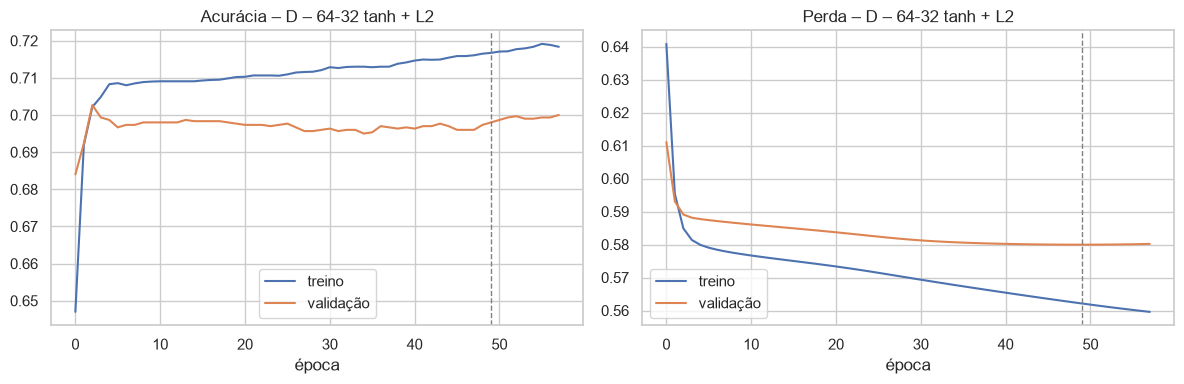

Acurácia treino=0.7197 | validação=0.6980 | diferença=+0.0217


In [9]:
h = historicos[melhor]; m = modelos[melhor]
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(h["accuracy"], label="treino"); ax[0].plot(h["val_accuracy"], label="validação"); ax[0].set_title(f"Acurácia – {melhor}"); ax[0].set_xlabel("época"); ax[0].legend()
ax[1].plot(h["loss"], label="treino"); ax[1].plot(h["val_loss"], label="validação"); ax[1].set_title(f"Perda – {melhor}"); ax[1].set_xlabel("época"); ax[1].legend()
for a in ax: a.axvline(resultados[melhor]["melhor_epoca"]-1, color="gray", ls="--", lw=1)
plt.tight_layout(); plt.show()
r = resultados[melhor]
print(f"Acurácia treino={r['train_acc']:.4f} | validação={r['val_acc']:.4f} | diferença={r['train_acc']-r['val_acc']:+.4f}")

TESTE: {'acc': 0.7193, 'precision': 0.6396, 'recall': 0.4572, 'f1': 0.5333}
Baseline no teste (sempre furto): acc = 0.6493
              precision    recall  f1-score   support

       furto      0.746     0.861     0.799      1948
       roubo      0.640     0.457     0.533      1052

    accuracy                          0.719      3000
   macro avg      0.693     0.659     0.666      3000
weighted avg      0.709     0.719     0.706      3000



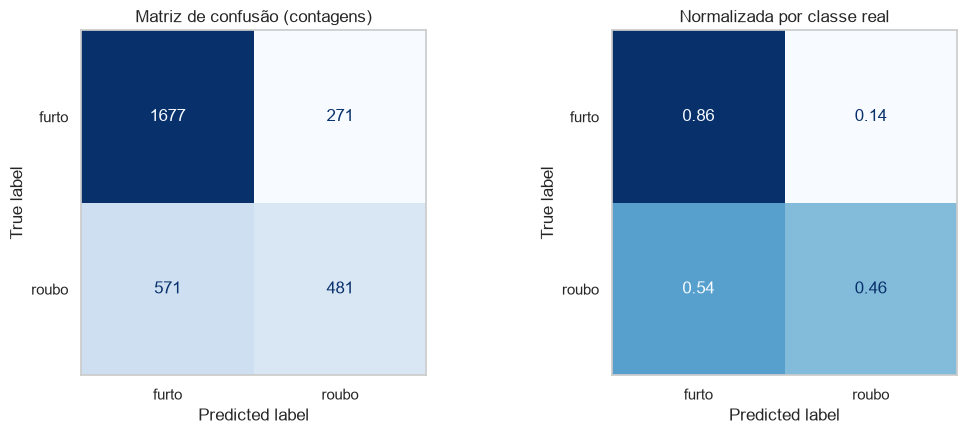

In [10]:
pte = m.predict(Xte, verbose=0).ravel(); yh = (pte >= 0.5).astype(int)
teste = metricas(y_te, pte); print("TESTE:", {k: round(v, 4) for k, v in teste.items()})
print("Baseline no teste (sempre furto): acc =", round(1 - y_te.mean(), 4))
print(classification_report(y_te, yh, target_names=["furto","roubo"], digits=3))
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y_te, yh), display_labels=["furto","roubo"]).plot(ax=ax[0], cmap="Blues", colorbar=False); ax[0].set_title("Matriz de confusão (contagens)")
ConfusionMatrixDisplay(confusion_matrix(y_te, yh, normalize="true"), display_labels=["furto","roubo"]).plot(ax=ax[1], cmap="Blues", colorbar=False, values_format=".2f"); ax[1].set_title("Normalizada por classe real")
for a in ax: a.grid(False)
plt.tight_layout(); plt.show()

### Análise de overfitting / underfitting

Dá pra olhar as curvas acima junto com a tabela da 6.1:

- A diferença treino × validação (acurácia) e a distância entre as curvas de perda mostram o grau de overfitting. A linha tracejada marca a época que o early stopping restaurou
- Modelo pequeno demais fica com perda alta em treino **e** validação (underfitting). Modelo grande que continua melhorando no treino enquanto a validação piora é overfitting
- O baseline e a regressão logística servem de régua: se a MLP não supera eles de forma clara, o ganho de capacidade não compensa

## 8. Exportação para a aplicação web

In [11]:
import os, joblib
os.makedirs("models", exist_ok=True)
m.save("models/mlp_roubo_furto.keras"); joblib.dump(enc, "models/encoder.joblib")
# pesos em .npz: o app web faz a inferência só com NumPy (sem TensorFlow) -> deploy leve
dense = [l for l in m.layers if isinstance(l, tf.keras.layers.Dense)]
acts = [l.activation.__name__ for l in dense]
np.savez("models/mlp_weights.npz", **{f"W{i}": l.get_weights()[0] for i, l in enumerate(dense)}, **{f"b{i}": l.get_weights()[1] for i, l in enumerate(dense)})
meta = dict(features=FEATURES, categorias={f: [str(c) for c in cats] for f, cats in zip(FEATURES, enc.categories_)},
            ativacoes=acts, modelo=melhor, metricas_teste=teste,
            arquiteturas={k: {kk: (float(vv) if not isinstance(vv, int) else vv) for kk, vv in v.items()} for k, v in resultados.items()},
            n_registros=int(len(df)), pct_roubo=float(df.alvo.mean()))
json.dump(meta, open("models/meta.json", "w", encoding="utf-8"), ensure_ascii=False, indent=1)
# checagem: inferência NumPy == Keras
Ws = [np.load("models/mlp_weights.npz")[f"W{i}"] for i in range(len(dense))]; bs = [np.load("models/mlp_weights.npz")[f"b{i}"] for i in range(len(dense))]
def forward(x):
    for W, b, a in zip(Ws, bs, acts):
        x = x @ W + b; x = np.maximum(x, 0) if a == "relu" else np.tanh(x) if a == "tanh" else 1/(1+np.exp(-x))
    return x.ravel()
print("diferença máxima NumPy × Keras:", float(np.abs(forward(Xte) - pte).max()))
json.dump({"hist": {k: {kk: [float(x) for x in vv] for kk, vv in v.items()} for k, v in historicos.items()}}, open("reports/historicos.json", "w", encoding="utf-8"))
fig_cm = confusion_matrix(y_te, yh).tolist(); json.dump(dict(cm=fig_cm, teste=teste), open("reports/teste.json", "w", encoding="utf-8"))

diferença máxima NumPy × Keras: 1.1920928955078125e-07


## 9. Conclusões

O melhor modelo pela validação foi o **D (64-32, tanh, L2, lr = 5e-4)**, com F1 (roubo) = 0,509 na validação. No teste, que só foi usado uma vez, deu acurácia 71,9%, precision 64,0%, recall 45,7% e F1 53,3%

O ganho é modesto. O baseline "sempre furto" acerta 64,9% e a regressão logística 69,9% na validação. A MLP melhora uns 7 p.p. sobre o baseline, mas fica praticamente empatada com a regressão logística

As quatro arquiteturas empataram: a acurácia de validação variou só de 69,6% a 70,0%, e o F1, de 0,499 a 0,509. Com 3.000 exemplos de validação, diferença desse tamanho tá dentro do ruído amostral. Então a escolha de D é defensável (foi a que teve o maior F1 na validação, que é o critério de seleção), mas não prova que ela seja "melhor" de forma robusta. O gargalo parece estar nos atributos e não na capacidade da rede: aumentar camadas e neurônios (B, C) não ajudou

Sobre overfitting e underfitting: B e C atingem o mínimo de perda de validação logo na época 5 e depois passam a decorar o treino, o que o early stopping corta. Nas quatro a diferença de acurácia entre treino e validação fica por volta de 2 p.p. (na D, 2,2 p.p.). Nenhum modelo mostra underfitting grave: o erro alto é comum a todos e vem da pouca informação nas entradas

O erro mais comum é classificar roubo como furto (recall de roubo de 46%): o modelo acerta 86% dos furtos, mas deixa passar mais da metade dos roubos. Isso é coerente com a classe minoritária (35%) e com atributos pouco discriminantes. Um limiar menor que 0,5 aumentaria o recall à custa de precision

### Limitações

Os atributos de contexto não separam bem roubo de furto (os dois acontecem majoritariamente em via pública). Os campos que realmente diferenciariam (arma, violência, qualificadoras) foram excluídos de propósito por serem vazamento de informação

A base é só de celulares, 2026 (jan–set) e capital, então não dá pra generalizar pra outros objetos, períodos ou cidades

Um BO de roubo/furto pode estar sub-registrado ou classificado de forma diferente entre delegacias, e o rótulo é o da natureza apurada no BO

A validação tem 3.000 exemplos. Pra afirmar qual arquitetura é melhor de verdade seria preciso validação cruzada e várias sementes

Por último: o modelo classifica o tipo de uma ocorrência já descrita. Ele não estima risco de crime em bairro nem horário nenhum

### Próximos passos

Testar hora exata (em vez de faixa), mês e variáveis geográficas mais finas (distrito/setor). Ajustar o limiar de decisão. E usar validação cruzada junto com embeddings pro bairro